## 1 — Load csv files as pandas DataFrames and display basic informations

In [18]:
import IPython
import pandas as pd
from IPython.display import display

flows1 = pd.read_csv('lab1/flows1.csv')
flows2 = pd.read_csv('lab1/flows2.csv')
hosts = pd.read_csv('lab1/hosts.csv')


print("flows1: length =", len(flows1), ", shape =", flows1.shape)  
print("flows2: length =", len(flows2), ", shape =", flows2.shape)
print("hosts: length =", len(hosts), ", shape =", hosts.shape)

print("\n--- flows1.info() ---")
flows1.info()  

print("\n--- flows2.info() ---")
flows2.info()

print("\n--- hosts.info() ---")
hosts.info()


print("\n--- Preview of flows1 ---")
display(flows1.head())  

print("\n--- Preview of flows2 ---")
display(flows2.head())

print("\n--- Preview of hosts ---")
display(hosts.head())

flows1: length = 21 , shape = (21, 10)
flows2: length = 26 , shape = (26, 11)
hosts: length = 20 , shape = (20, 8)

--- flows1.info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   flow_id   21 non-null     int64  
 1   src_ip    21 non-null     object 
 2   dst_ip    21 non-null     object 
 3   src_port  21 non-null     int64  
 4   dst_port  21 non-null     int64  
 5   protocol  21 non-null     object 
 6   bytes     17 non-null     float64
 7   packets   21 non-null     int64  
 8   date      21 non-null     object 
 9   label     20 non-null     object 
dtypes: float64(1), int64(4), object(5)
memory usage: 1.8+ KB

--- flows2.info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -

,flow_id,src_ip,dst_ip,src_port,dst_port,protocol,bytes,packets,date,label
0,1,10.0.0.1,8.8.8.8,34567,53,UDP,1200.0,10,2025-09-01 08:13:27,benign
1,2,10.0.0.2,1.2.3.4,45678,80,TCP,15000.0,80,2025-09-01 09:45:10,malicious
2,3,10.0.0.3,9.9.9.9,56789,443,TCP,NaN,40,2025-09-02 00:12:05,benign
3,4,10.0.0.1,8.8.8.8,34567,53,UDP,1200.0,10,2025-09-02 14:23:01,benign
4,5,10.0.0.4,5.6.7.8,23456,22,TCP,9999999.0,500,2025-09-03 07:05:59,NaN



--- Preview of flows2 ---


,id,source,dest,src_port,dest_port,protocol,kbytes,packets,timestamp,outcome,session_duration_seconds
0,101,10.0.0.6,8.8.8.8,40000,53,UDP,1.269531,12,2025/09/01 14:23:01,benign,2.1
1,102,10.0.0.7,1.2.3.4,41000,80,TCP,15.625000,90,2025/09/01 15:10:00,malicious,1.5
2,103,10.0.0.8,9.9.9.9,42000,443,TCP,NaN,50,2025/09/02 09:05:00,benign,0.9
3,104,10.0.0.1,8.8.8.8,34567,53,UDP,1.171875,10,2025/09/02 14:23:01,benign,2.1
4,105,10.0.0.9,5.6.7.8,43000,22,TCP,11718.750000,600,2025/09/03 08:00:00,unknown,12.0



--- Preview of hosts ---


,ip,hostname,os,last_seen,owner,cpu_percent,mem_percent,anomaly_score
0,10.0.0.1,host-A,Linux,2025-09-02 07:12:03,alice,2.3,30.1,0.02
1,10.0.0.2,host-B,Linux,2025-09-01 13:00:00,bob,55.0,70.0,NaN
2,10.0.0.3,host-C,Windows,2025-09-02 09:05:00,carol,5.1,20.0,0.01
3,10.0.0.4,host-D,Linux,2025-09-02 22:45:10,dave,95.0,95.0,0.90
4,10.0.0.5,host-E,Linux,2025-09-02 08:30:00,eve,27.8,19.8,0.00


## 2- Identify Common Columns Between flows1 and flows2, and Rename them In-Place to Match

In [19]:
print("columns of flows1:", flows1.columns.tolist())
print("columns of flows2:", flows2.columns.tolist())

flows1.rename(columns={'date': 'datetime'}, inplace=True)
flows2.rename(columns={'id': 'flow_id', 'source': 'src_ip','dest': 'dst_ip','timestamp': 'datetime', 'kbytes': 'bytes','outcome': 'label'}, inplace=True)

if 'bytes' in flows2.columns:
    flows2['bytes'] = flows2['bytes'] * 1024
    
print("\nafter rename -> flows1 cols :",flows1.columns.tolist())
print("after rename -> flows2 cols :",flows2.columns.tolist()) 


columns of flows1: ['flow_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol', 'bytes', 'packets', 'date', 'label']
columns of flows2: ['id', 'source', 'dest', 'src_port', 'dest_port', 'protocol', 'kbytes', 'packets', 'timestamp', 'outcome', 'session_duration_seconds']

after rename -> flows1 cols : ['flow_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol', 'bytes', 'packets', 'datetime', 'label']
after rename -> flows2 cols : ['flow_id', 'src_ip', 'dst_ip', 'src_port', 'dest_port', 'protocol', 'bytes', 'packets', 'datetime', 'label', 'session_duration_seconds']


## 3- Drop non-common columns between flows1 and flows2 In-Place

In [20]:
print("flows1 to delete")
print("columns of flows1:", flows1.columns.tolist())
print("columns of flows2:", flows2.columns.tolist())

flows1.drop(columns=['flow_id'], errors='ignore', inplace=True)
flows2.drop(columns=['flow_id', 'session_duration_seconds'], errors='ignore', inplace=True)

print("\nafter deleting -> flows1 cols :",flows1.columns.tolist())
print("\nafter deleting -> flows2 cols :",flows2.columns.tolist())

flows1 to delete
columns of flows1: ['flow_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol', 'bytes', 'packets', 'datetime', 'label']
columns of flows2: ['flow_id', 'src_ip', 'dst_ip', 'src_port', 'dest_port', 'protocol', 'bytes', 'packets', 'datetime', 'label', 'session_duration_seconds']

after deleting -> flows1 cols : ['src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol', 'bytes', 'packets', 'datetime', 'label']

after deleting -> flows2 cols : ['src_ip', 'dst_ip', 'src_port', 'dest_port', 'protocol', 'bytes', 'packets', 'datetime', 'label']


## 4- Ensure all common columns are normalized to the same format

### Convert numeric fields (ports, packets, bytes) to numeric safely

In [21]:
numeric_columns_flows = ['src_port', 'dst_port', 'packets', 'bytes']  

for col in numeric_columns_flows:
    if col in flows1.columns:
        flows1[col] = pd.to_numeric(flows1[col], errors='coerce')  
    if col in flows2.columns:
        flows2[col] = pd.to_numeric(flows2[col], errors='coerce')

### Normalize datetime to standard datetime64 format  and convert numerical values to float

In [22]:
datetime_columns = ['datetime', 'last_seen']  

for col in datetime_columns:
    if col in flows1.columns:
        flows1[col] = pd.to_datetime(flows1[col], errors='coerce')
    if col in flows2.columns:
        flows2[col] = pd.to_datetime(flows2[col], errors='coerce')
    if col in hosts.columns:
        hosts[col] = pd.to_datetime(hosts[col], errors='coerce')  



numeric_columns_hosts = ['packets', 'bytes', 'cpu_load', 'memory_usage']  

for col in numeric_columns_hosts:
    if col in hosts.columns:
        hosts[col] = pd.to_numeric(hosts[col], errors='coerce')




### Convert label-type fields into Categorical (for efficient analysis)

In [23]:
label_columns = [ 'label']  

for df in [flows1, flows2, hosts]:
    for col in label_columns:
        if col in df.columns:
            df[col] = df[col].astype('category')

print("\nflows1 dtypes:\n", flows1.dtypes)
print("\nflows2 dtypes:\n", flows2.dtypes)
print("\nhosts dtypes:\n", hosts.dtypes)


flows1 dtypes:
 src_ip              object
dst_ip              object
src_port             int64
dst_port             int64
protocol            object
bytes              float64
packets              int64
datetime    datetime64[ns]
label             category
dtype: object

flows2 dtypes:
 src_ip               object
dst_ip               object
src_port              int64
dest_port             int64
protocol             object
bytes               float64
packets               int64
datetime     datetime64[ns]
label              category
dtype: object

hosts dtypes:
 ip                       object
hostname                 object
os                       object
last_seen        datetime64[ns]
owner                    object
cpu_percent             float64
mem_percent             float64
anomaly_score           float64
dtype: object


## 5- Concatenate flows1 and flows2 vertically

In [24]:
flows1_aligned = flows1.reindex(columns=flows1.columns)
flows2_aligned = flows2.reindex(columns=flows1.columns)

print("Before merge:")
print("flows1 rows =", len(flows1_aligned))
print("flows2 rows =", len(flows2_aligned))

# 4. Concatenate vertically
merged_flows = pd.concat([flows1_aligned, flows2_aligned], axis=0, ignore_index=True)

# 5. Verify merge
print("\nAfter merge:")
print("merged_flows rows =", len(merged_flows))
print("Expected =", len(flows1_aligned) + len(flows2_aligned))

display(merged_flows)

Before merge:
flows1 rows = 21
flows2 rows = 26

After merge:
merged_flows rows = 47
Expected = 47


,src_ip,dst_ip,src_port,dst_port,protocol,bytes,packets,datetime,label
0,10.0.0.1,8.8.8.8,34567,53.0,UDP,1200.0,10,2025-09-01 08:13:27,benign
1,10.0.0.2,1.2.3.4,45678,80.0,TCP,15000.0,80,2025-09-01 09:45:10,malicious
2,10.0.0.3,9.9.9.9,56789,443.0,TCP,NaN,40,2025-09-02 00:12:05,benign
3,10.0.0.1,8.8.8.8,34567,53.0,UDP,1200.0,10,2025-09-02 14:23:01,benign
4,10.0.0.4,5.6.7.8,23456,22.0,TCP,9999999.0,500,2025-09-03 07:05:59,NaN
5,10.0.0.7,5.6.7.8,1884,80.0,TCP,NaN,10,NaT,benign
6,10.0.0.11,4.4.4.4,45155,80.0,TCP,1200.0,40,2025-09-02 22:27:24,benign
7,10.0.0.5,8.8.8.8,54731,53.0,TCP,20000.0,5,2025-09-01 06:33:12,benign
8,10.0.0.10,5.6.7.8,3771,80.0,UDP,20000.0,5,2025-09-03 11:11:11,malicious
9,10.0.0.7,4.4.4.4,61256,53.0,UDP,500.0,40,2025-09-02 04:44:44,benign


## 6- Join the concatenated flows with hosts (horizontally) using IP as key

In [25]:
# 6) HORIZONTAL JOIN with hosts on dst_ip -> ip
merged_flows_hosts = merged_flows.merge(hosts, how='left', left_on='src_ip', right_on='ip')
display(merged_flows_hosts)

,src_ip,dst_ip,src_port,dst_port,protocol,bytes,packets,datetime,label,ip,hostname,os,last_seen,owner,cpu_percent,mem_percent,anomaly_score
0,10.0.0.1,8.8.8.8,34567,53.0,UDP,1200.0,10,2025-09-01 08:13:27,benign,10.0.0.1,host-A,Linux,2025-09-02 07:12:03,alice,2.3,30.1,0.02
1,10.0.0.2,1.2.3.4,45678,80.0,TCP,15000.0,80,2025-09-01 09:45:10,malicious,10.0.0.2,host-B,Linux,2025-09-01 13:00:00,bob,55.0,70.0,NaN
2,10.0.0.3,9.9.9.9,56789,443.0,TCP,NaN,40,2025-09-02 00:12:05,benign,10.0.0.3,host-C,Windows,2025-09-02 09:05:00,carol,5.1,20.0,0.01
3,10.0.0.1,8.8.8.8,34567,53.0,UDP,1200.0,10,2025-09-02 14:23:01,benign,10.0.0.1,host-A,Linux,2025-09-02 07:12:03,alice,2.3,30.1,0.02
4,10.0.0.4,5.6.7.8,23456,22.0,TCP,9999999.0,500,2025-09-03 07:05:59,NaN,10.0.0.4,host-D,Linux,2025-09-02 22:45:10,dave,95.0,95.0,0.90
5,10.0.0.7,5.6.7.8,1884,80.0,TCP,NaN,10,NaT,benign,10.0.0.7,host-G,MacOS,2025-09-01 02:05:05,eve,12.7,63.7,NaN
6,10.0.0.11,4.4.4.4,45155,80.0,TCP,1200.0,40,2025-09-02 22:27:24,benign,10.0.0.11,host-K,Windows,2025-09-03 12:12:12,eve,2.9,28.4,NaN
7,10.0.0.5,8.8.8.8,54731,53.0,TCP,20000.0,5,2025-09-01 06:33:12,benign,10.0.0.5,host-E,Linux,2025-09-02 08:30:00,eve,27.8,19.8,0.00
8,10.0.0.10,5.6.7.8,3771,80.0,UDP,20000.0,5,2025-09-03 11:11:11,malicious,10.0.0.10,host-J,Windows,2025-09-02 19:19:19,frank,7.6,58.1,0.01
9,10.0.0.7,4.4.4.4,61256,53.0,UDP,500.0,40,2025-09-02 04:44:44,benign,10.0.0.7,host-G,MacOS,2025-09-01 02:05:05,eve,12.7,63.7,NaN


## Visualize All Columns from the Merged Dataset

Numeric columns: ['src_port', 'dst_port', 'bytes', 'packets', 'cpu_percent', 'mem_percent', 'anomaly_score']
Non-numeric columns: ['src_ip', 'dst_ip', 'protocol', 'datetime', 'label', 'ip', 'hostname', 'os', 'last_seen', 'owner']


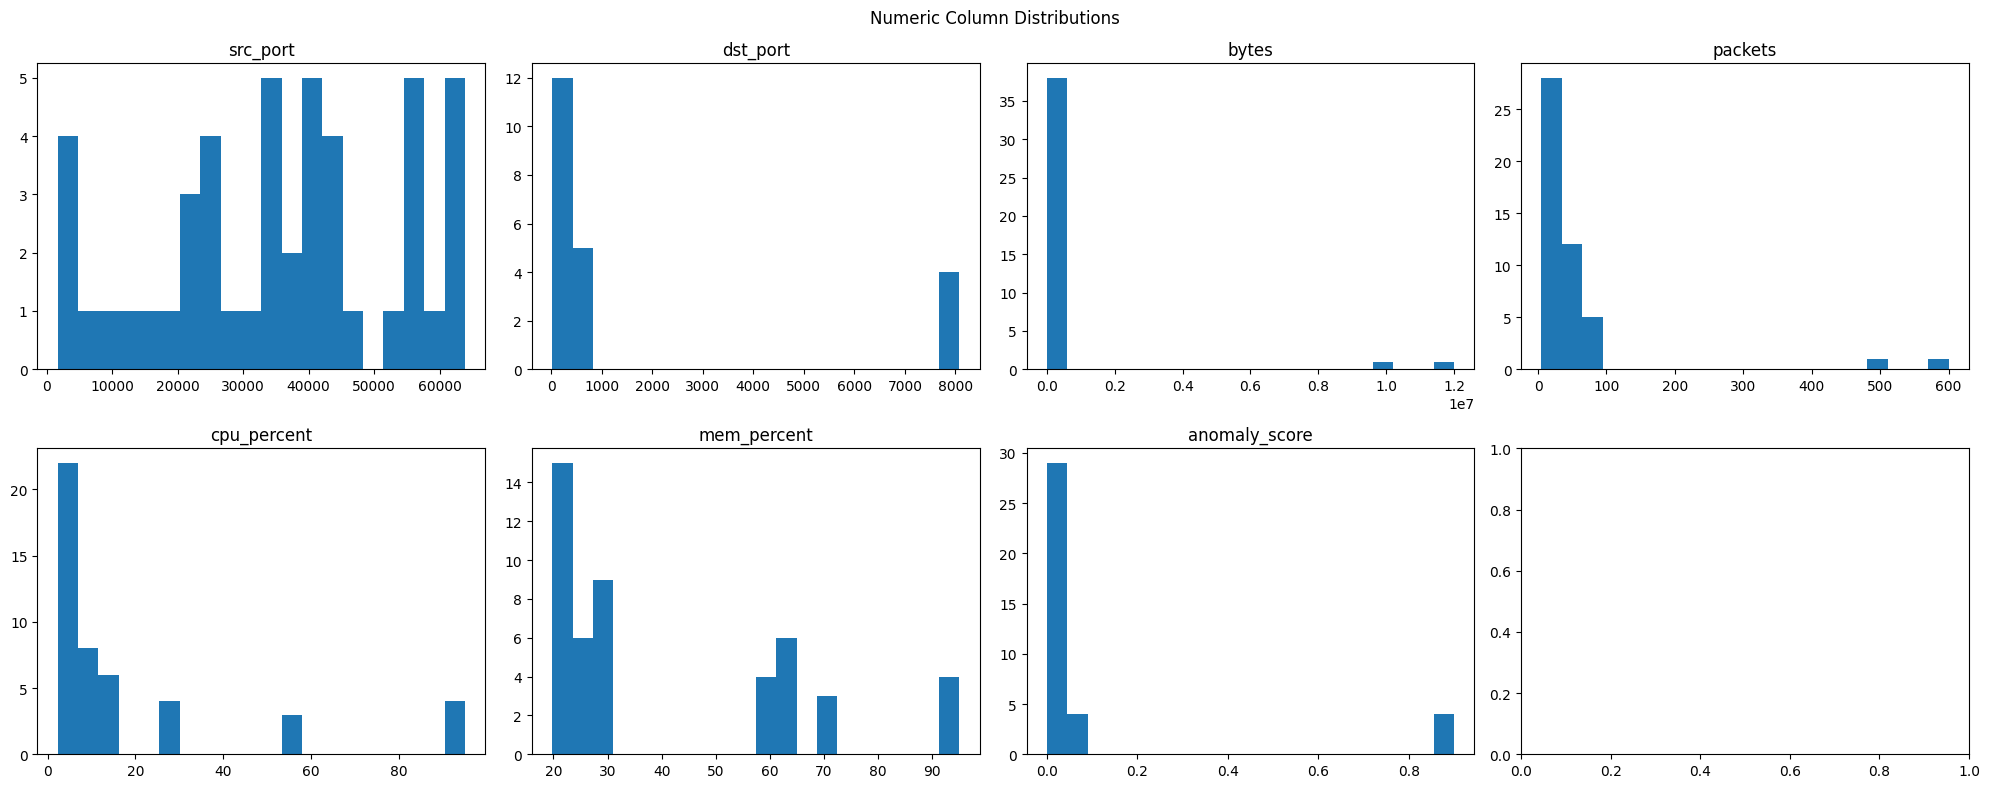

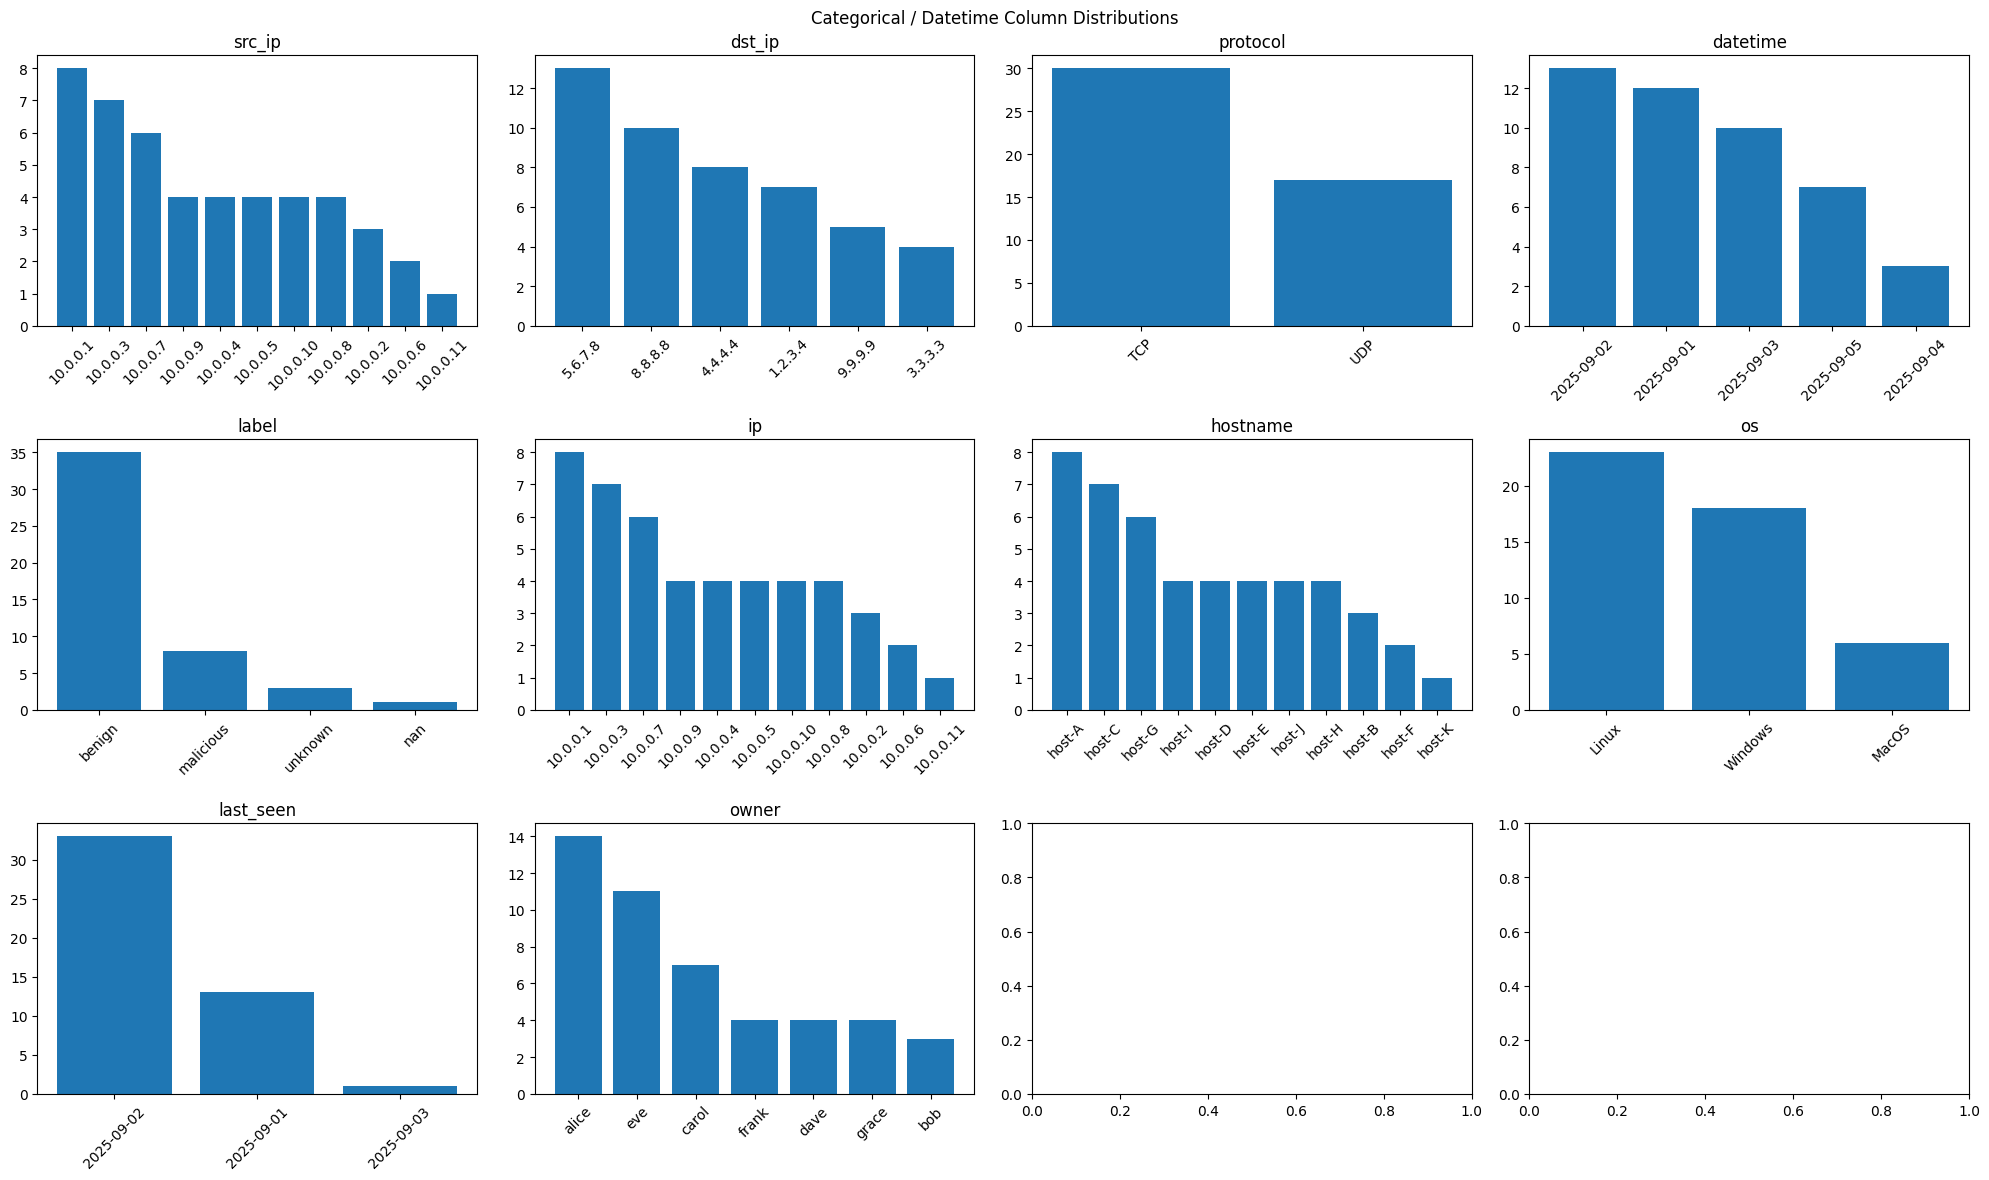

In [26]:
import matplotlib.pyplot as plt

# 📊 Compact Visualization of All Columns in Subplots

numeric_cols = merged_flows_hosts.select_dtypes(include=['number']).columns
non_numeric_cols = merged_flows_hosts.select_dtypes(exclude=['number']).columns

print("Numeric columns:", list(numeric_cols))
print("Non-numeric columns:", list(non_numeric_cols))

# ------------------------------------
# 1️⃣ NUMERIC COLUMNS: histograms grid
# ------------------------------------
if len(numeric_cols) > 0:
    n = len(numeric_cols)
    cols_per_row = 4
    rows = (n + cols_per_row - 1) // cols_per_row

    fig, axes = plt.subplots(rows, cols_per_row, figsize=(5 * cols_per_row, 4 * rows))
    axes = axes.flatten()

    for i, col in enumerate(numeric_cols):
        axes[i].hist(merged_flows_hosts[col].dropna(), bins=20)
        axes[i].set_title(col)

    plt.suptitle("Numeric Column Distributions")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns found.")


# ------------------------------------
# 2️⃣ CATEGORICAL COLUMNS: bar charts grid
# ------------------------------------

if len(non_numeric_cols) > 0:
    n = len(non_numeric_cols)
    cols_per_row = 4
    rows = (n + cols_per_row - 1) // cols_per_row

    fig, axes = plt.subplots(rows, cols_per_row, figsize=(5 * cols_per_row, 4 * rows))
    axes = axes.flatten()

    for i, col in enumerate(non_numeric_cols):
        
        if str(merged_flows_hosts[col].dtype).startswith('datetime'):
            data = merged_flows_hosts[col].dropna().dt.date.value_counts()
        else:
            data = merged_flows_hosts[col].value_counts(dropna=False)

        axes[i].bar(data.index.astype(str), data.values)
        axes[i].set_title(col)
        axes[i].tick_params(axis='x', rotation=45)

    plt.suptitle("Categorical / Datetime Column Distributions")
    plt.tight_layout()
    plt.show()
else:
    print("No categorical/datetime columns found.")




## 8 — Identify Missing Values and Drop Rows with Nulls in Critical Columns

In [27]:

# === 8 — Identify Missing Values and Drop Rows with Nulls in Critical Columns ===

# 1. Inspect missing values
print("Before cleaning:")
merged_flows_hosts.info()

# 2. Define critical columns (adjust if needed)
critical_cols = ['src_ip', 'dst_ip', 'datetime', 'label']  # Add/remove as necessary

# 3. Count rows before
before = len(merged_flows_hosts)

# 4. Drop rows with missing values in critical fields
merged_flows_hosts.dropna(subset=critical_cols, inplace=True)

# 5. Count rows after
after = len(merged_flows_hosts)
print(f"\nDropped {before - after} rows missing critical fields")

# 6. Verify cleaned dataset
print("\nAfter cleaning:")
merged_flows_hosts.info()





Before cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   src_ip         47 non-null     object        
 1   dst_ip         47 non-null     object        
 2   src_port       47 non-null     int64         
 3   dst_port       21 non-null     float64       
 4   protocol       47 non-null     object        
 5   bytes          40 non-null     float64       
 6   packets        47 non-null     int64         
 7   datetime       45 non-null     datetime64[ns]
 8   label          46 non-null     object        
 9   ip             47 non-null     object        
 10  hostname       47 non-null     object        
 11  os             47 non-null     object        
 12  last_seen      47 non-null     datetime64[ns]
 13  owner          47 non-null     object        
 14  cpu_percent    47 non-null     float64       
 15  mem_perc

## 8 —1 Fill Missing Values in Non-Critical Columns Using Pandas

In [28]:
# === 8 — Fill Missing in Non-Critical Columns via Median ===

# 1. Median fill for 'bytes'
bytes_median = merged_flows_hosts['bytes'].median()
merged_flows_hosts['bytes'] = merged_flows_hosts['bytes'].fillna(bytes_median)

print(f"Pandas median imputation for bytes used value: {bytes_median}")

# 2. Median fill for 'anomaly_score'
anomaly_median = merged_flows_hosts['anomaly_score'].median()
merged_flows_hosts['anomaly_score'] = merged_flows_hosts['anomaly_score'].fillna(anomaly_median)

print(f"Pandas median imputation for anomaly_score used value: {anomaly_median}")

#  verify no nulls left in these columns
print(merged_flows_hosts[['bytes', 'anomaly_score']].isna().sum())


Pandas median imputation for bytes used value: 3500.0
Pandas median imputation for anomaly_score used value: 0.01
bytes            0
anomaly_score    0
dtype: int64


## Remove duplicate rows

In [29]:
# === 9) REMOVE DUPLICATES ===

# 1. Find duplicates (full row match or subset-based)
duplicates = merged_flows_hosts[merged_flows_hosts.duplicated(keep=False)]

print("Duplicate rows:")
print(duplicates)

# 2. Drop duplicates — full-row comparison
before = len(merged_flows_hosts)
merged_flows_hosts.drop_duplicates(subset=['src_ip', 'dst_ip', 'datetime'],inplace=True,ignore_index=True)
after = len(merged_flows_hosts)

print(f"Dropped duplicates: {before - after}")





Duplicate rows:
      src_ip   dst_ip  src_port  dst_port protocol   bytes  packets  \
2   10.0.0.3  9.9.9.9     56789     443.0      TCP  3500.0       40   
20  10.0.0.3  9.9.9.9     56789     443.0      TCP  3500.0       40   
44  10.0.0.4  1.2.3.4     63301       NaN      UDP  3500.0        6   
46  10.0.0.4  1.2.3.4     63301       NaN      UDP  3500.0        6   

              datetime   label        ip hostname       os  \
2  2025-09-02 00:12:05  benign  10.0.0.3   host-C  Windows   
20 2025-09-02 00:12:05  benign  10.0.0.3   host-C  Windows   
44 2025-09-05 11:43:04  benign  10.0.0.4   host-D    Linux   
46 2025-09-05 11:43:04  benign  10.0.0.4   host-D    Linux   

             last_seen  owner  cpu_percent  mem_percent  anomaly_score  
2  2025-09-02 09:05:00  carol          5.1         20.0           0.01  
20 2025-09-02 09:05:00  carol          5.1         20.0           0.01  
44 2025-09-02 22:45:10   dave         95.0         95.0           0.90  
46 2025-09-02 22:45:10   

## Remove outliers with IQR (Interquartile Range)

In [30]:
# === 10) REMOVE OUTLIERS WITH IQR (bytes column) ===

Q1 = merged_flows_hosts['bytes'].quantile(0.25)
Q3 = merged_flows_hosts['bytes'].quantile(0.75)
IQR = Q3 - Q1

low_bound = Q1 - 1.5 * IQR
high_bound = Q3 + 1.5 * IQR

print(f"Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, Low={low_bound:.2f}, High={high_bound:.2f}")

# Locate rows to remove
outliers = merged_flows_hosts[
    (merged_flows_hosts['bytes'] < low_bound) | (merged_flows_hosts['bytes'] > high_bound)
]

print("Outlier rows (to be removed):")
print(outliers)

# Drop them
before = len(merged_flows_hosts)
merged_flows_hosts = merged_flows_hosts[
    (merged_flows_hosts['bytes'] >= low_bound) & (merged_flows_hosts['bytes'] <= high_bound)
].reset_index(drop=True)
after = len(merged_flows_hosts)

print(f"IQR removed: {before - after} rows")



Q1=1300.00, Q3=20000.00, IQR=18700.00, Low=-26750.00, High=48050.00
Outlier rows (to be removed):
      src_ip   dst_ip  src_port  dst_port protocol       bytes  packets  \
21  10.0.0.9  5.6.7.8     43000       NaN      TCP  12000000.0      600   

              datetime    label        ip hostname     os           last_seen  \
21 2025-09-03 08:00:00  unknown  10.0.0.9   host-I  Linux 2025-09-02 06:30:30   

    owner  cpu_percent  mem_percent  anomaly_score  
21  alice          3.2         26.0            0.0  
IQR removed: 1 rows


## Save the result as csv file

In [31]:
# Save cleaned dataframe to CSV
merged_flows_hosts.to_csv("clean_merged_data.csv", index=False)  

clean_merged_data = pd.read_csv("clean_merged_data.csv")

# Show the first few rows
from IPython.display import display
display(clean_merged_data.head())

...

,src_ip,dst_ip,src_port,dst_port,protocol,bytes,packets,datetime,label,ip,hostname,os,last_seen,owner,cpu_percent,mem_percent,anomaly_score
0,10.0.0.1,8.8.8.8,34567,53.0,UDP,1200.0,10,2025-09-01 08:13:27,benign,10.0.0.1,host-A,Linux,2025-09-02 07:12:03,alice,2.3,30.1,0.02
1,10.0.0.2,1.2.3.4,45678,80.0,TCP,15000.0,80,2025-09-01 09:45:10,malicious,10.0.0.2,host-B,Linux,2025-09-01 13:00:00,bob,55.0,70.0,0.01
2,10.0.0.3,9.9.9.9,56789,443.0,TCP,3500.0,40,2025-09-02 00:12:05,benign,10.0.0.3,host-C,Windows,2025-09-02 09:05:00,carol,5.1,20.0,0.01
3,10.0.0.1,8.8.8.8,34567,53.0,UDP,1200.0,10,2025-09-02 14:23:01,benign,10.0.0.1,host-A,Linux,2025-09-02 07:12:03,alice,2.3,30.1,0.02
4,10.0.0.11,4.4.4.4,45155,80.0,TCP,1200.0,40,2025-09-02 22:27:24,benign,10.0.0.11,host-K,Windows,2025-09-03 12:12:12,eve,2.9,28.4,0.01


Ellipsis

## Encode categorical data for ML model training

In [35]:
# 12 — Encode categorical data for ML model training

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
import numpy as np


# 1) Keep only 'benign' and 'malicious' labels
df = clean_merged_data[clean_merged_data['label'].isin(['benign', 'malicious'])].copy()
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
import numpy as np

# 1) Filter to keep only benign/malicious rows
df = clean_merged_data[clean_merged_data['label'].isin(['benign', 'malicious'])].copy()

# 2) Convert datetime
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')

# 3) Extract temporal + internal features
df['hour'] = df['datetime'].dt.hour
df['weekday'] = df['datetime'].dt.weekday
df['src_internal'] = df['src_ip'].astype(str).str.startswith('10.').astype(int)
df['dst_internal'] = df['dst_ip'].astype(str).str.startswith('10.').astype(int)

# 4) Encode target
y = df['label'].map({'benign': 0, 'malicious': 1}).astype(int).to_numpy()

# 5) Define categorical & numeric features
categorical = ['protocol','hostname','os','owner']
numeric = ['bytes','packets','cpu_percent','mem_percent','hour','weekday','src_internal','dst_internal','anomaly_score']

# 6) One-hot encode
pre = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)
    ],
    remainder='passthrough'
)

X = pre.fit_transform(df[categorical + numeric])

# 7) Rebuild encoded DataFrame
encoded_cols = pre.named_transformers_['cat'].get_feature_names_out(categorical)
final_cols = list(encoded_cols) + numeric

encoded_df = pd.DataFrame(X, columns=final_cols)  # convert sparse to dense
encoded_df['target'] = y

print(f"✅ X shape: {X.shape} | y shape: {y.shape}")
display(encoded_df.head())


✅ X shape: (38, 32) | y shape: (38,)


,protocol_TCP,protocol_UDP,hostname_host-A,hostname_host-B,hostname_host-C,hostname_host-D,hostname_host-E,hostname_host-F,hostname_host-G,hostname_host-H,...,bytes,packets,cpu_percent,mem_percent,hour,weekday,src_internal,dst_internal,anomaly_score,target
0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1200.0,10.0,2.3,30.1,8.0,0.0,1.0,0.0,0.02,0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,15000.0,80.0,55.0,70.0,9.0,0.0,1.0,0.0,0.01,1
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,3500.0,40.0,5.1,20.0,0.0,1.0,1.0,0.0,0.01,0
3,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1200.0,10.0,2.3,30.1,14.0,1.0,1.0,0.0,0.02,0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1200.0,40.0,2.9,28.4,22.0,1.0,1.0,0.0,0.01,0


## Normalize values (Scaling)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

numeric = ['bytes','packets','cpu_percent','mem_percent','hour','weekday','src_internal','dst_internal','anomaly_score']

scaler = MinMaxScaler()

encoded_df[numeric] = scaler.fit_transform(encoded_df[numeric])

print("After MinMax Scaling:")
display(encoded_df)


After MinMax Scaling:


,protocol_TCP,protocol_UDP,hostname_host-A,hostname_host-B,hostname_host-C,hostname_host-D,hostname_host-E,hostname_host-F,hostname_host-G,hostname_host-H,...,bytes,packets,cpu_percent,mem_percent,hour,weekday,src_internal,dst_internal,anomaly_score,target
0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.028571,0.058824,0.000000,0.136968,0.363636,0.00,0.0,0.0,0.022222,0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.591837,0.882353,0.568501,0.667553,0.409091,0.00,0.0,0.0,0.011111,1
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.122449,0.411765,0.030205,0.002660,0.000000,0.25,0.0,0.0,0.011111,0
3,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.028571,0.058824,0.000000,0.136968,0.636364,0.25,0.0,0.0,0.022222,0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.028571,0.411765,0.006472,0.114362,1.000000,0.25,0.0,0.0,0.011111,0
5,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.795918,0.000000,0.275081,0.000000,0.272727,0.00,0.0,0.0,0.000000,0
6,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.795918,0.000000,0.057174,0.509309,0.500000,0.50,0.0,0.0,0.011111,1
7,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.000000,0.411765,0.112190,0.583777,0.181818,0.25,0.0,0.0,0.011111,0
8,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.795918,0.411765,0.057174,0.509309,0.863636,1.00,0.0,0.0,0.011111,1
9,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.795918,0.058824,0.030205,0.002660,0.000000,0.25,0.0,0.0,0.011111,0
